# Lab 8: DBSCAN Clustering


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

df = pd.read_csv("datasets/Wholesale customers data.csv")
df.head()


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [2]:
print(df.columns.tolist())
print(df.shape)


['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
(440, 8)


In [3]:
# Select spending columns that exist in this copy of the dataset
possible_columns = [
    "Fresh", "Milk", "Grocery", "Frozen",
    "Detergents_Paper", "Delicassen"
]
columns = [col for col in possible_columns if col in df.columns]

X = df[columns].copy()
X = X.fillna(X.median())

print("Columns used:", columns)
X.head()


Columns used: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [4]:
# Spending values can vary greatly, so scale them first
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [5]:
model = DBSCAN(eps=1.5, min_samples=5)
df["Cluster"] = model.fit_predict(X_scaled)

print("Cluster counts (-1 means noise):")
print(df["Cluster"].value_counts().sort_index())

cluster_count = len(set(df["Cluster"])) - (1 if -1 in set(df["Cluster"]) else 0)
print("Clusters excluding noise:", cluster_count)


Cluster counts (-1 means noise):
Cluster
-1     27
 0    413
Name: count, dtype: int64
Clusters excluding noise: 1


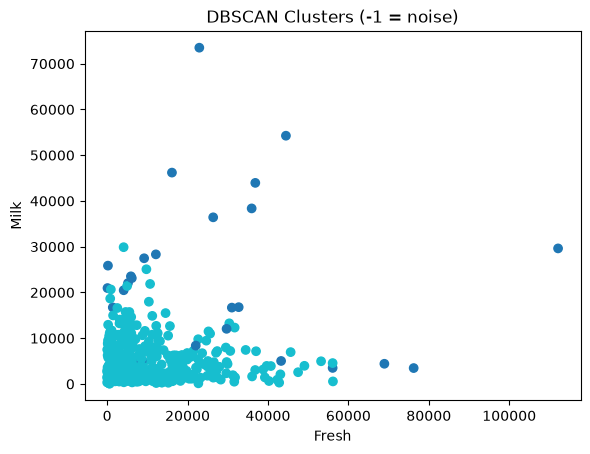

In [6]:
# Plot the first two spending columns
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=df["Cluster"], cmap="tab10")
plt.xlabel(columns[0])
plt.ylabel(columns[1])
plt.title("DBSCAN Clusters (-1 = noise)")
plt.show()
